**by: [João Ataíde](https://www.joaoataide.com)**
# **CAP 10: Análise Fatorial por Componentes Principais**

---



In [1]:
#importar bibliotecas
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from scipy.stats import chi2

A análise fatorial é uma técnica multivariada exploratória usada quando queremos estudar o comportamento conjunto de variáveis métricas e criar, a partir das correlações entre elas, novas variáveis chamadas `fatores`, que representam dimensões latentes por trás das variáveis originais.

Enquanto a análise de agrupamentos (capítulo 9) junta observações (linhas), a análise fatorial junta variáveis (colunas). Seus principais objetivos são:

* `Redução estrutural:` representar muitas variáveis por poucos fatores, perdendo pouca informação.
* `Criação de indicadores e rankings:` combinar as variáveis em um indicador de desempenho.
* `Validação de constructos:` verificar se variáveis que deveriam medir a mesma coisa se agrupam no mesmo fator.
* `Fatores ortogonais:` como os fatores não são correlacionados entre si, podem entrar em modelos de regressão sem problemas de multicolinearidade.

O método de extração mais usado, e o deste capítulo, é o de `componentes principais`.

`OBS:` *Assim como no capítulo 9, a técnica é exploratória e estática: se entrarem novas observações ou variáveis, os fatores precisam ser recalculados.*

## **Correlação de Pearson e Conceito de Fator**

O ponto de partida é a matriz de correlações $\rho$ entre as $k$ variáveis:

$\rho = \begin{bmatrix} 1 & \rho_{12} & \cdots & \rho_{1k} \\ \rho_{21} & 1 & \cdots & \rho_{2k} \\ \vdots & \vdots & \ddots & \vdots \\ \rho_{k1} & \rho_{k2} & \cdots & 1 \end{bmatrix}$

Variáveis com correlação alta (próxima de −1 ou 1) tendem a formar um mesmo fator, e variáveis com correlação próxima de 0 tendem a ficar em fatores diferentes.

Veja um exemplo hipotético com três variáveis, como nas Figuras 10.1 a 10.4 do livro: $X_1$ e $X_2$ são muito correlacionadas, e $X_3$ não tem relação com elas.

In [2]:
np.random.seed(42)
n = 60

# Situação hipotética: X1 e X2 correlacionadas, X3 independente
x1 = np.random.normal(5, 2, n)
x2 = 0.9 * x1 + np.random.normal(0, 0.6, n)
x3 = np.random.normal(5, 2, n)

hipotetico = pd.DataFrame({"X1": x1, "X2": x2, "X3": x3})
hipotetico.corr().round(3)

,X1,X2,X3
X1,1.000,0.948,0.111
X2,0.948,1.000,0.181
X3,0.111,0.181,1.000


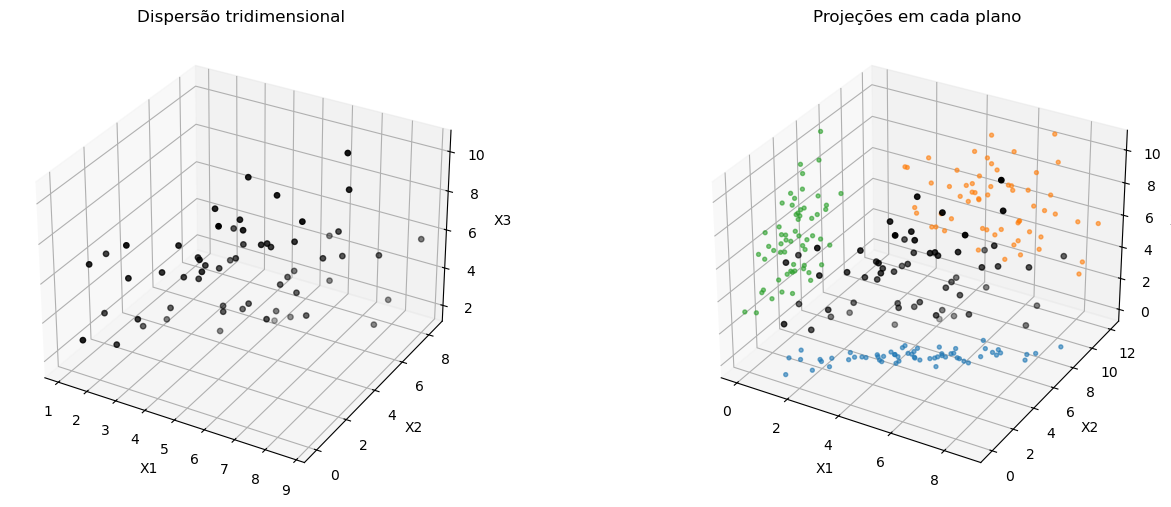

In [3]:
# Figuras 10.1 e 10.3: dispersão tridimensional e projeções nos planos
fig = plt.figure(figsize = (16, 6))

ax = fig.add_subplot(1, 2, 1, projection='3d')
ax.scatter(x1, x2, x3, color='black', s=15)
ax.set_title('Dispersão tridimensional')

ax = fig.add_subplot(1, 2, 2, projection='3d')
ax.scatter(x1, x2, x3, color='black', s=15)
ax.scatter(x1, x2, np.full(n, 0), color='C0', s=8, alpha=0.6)    # Projeção no plano X1-X2
ax.scatter(x1, np.full(n, 12), x3, color='C1', s=8, alpha=0.6)   # Projeção no plano X1-X3
ax.scatter(np.full(n, 0), x2, x3, color='C2', s=8, alpha=0.6)    # Projeção no plano X2-X3
ax.set_title('Projeções em cada plano')

for eixo in fig.axes:
    eixo.set_xlabel('X1')
    eixo.set_ylabel('X2')
    eixo.set_zlabel('X3')

# Exibir o gráfico
plt.show()

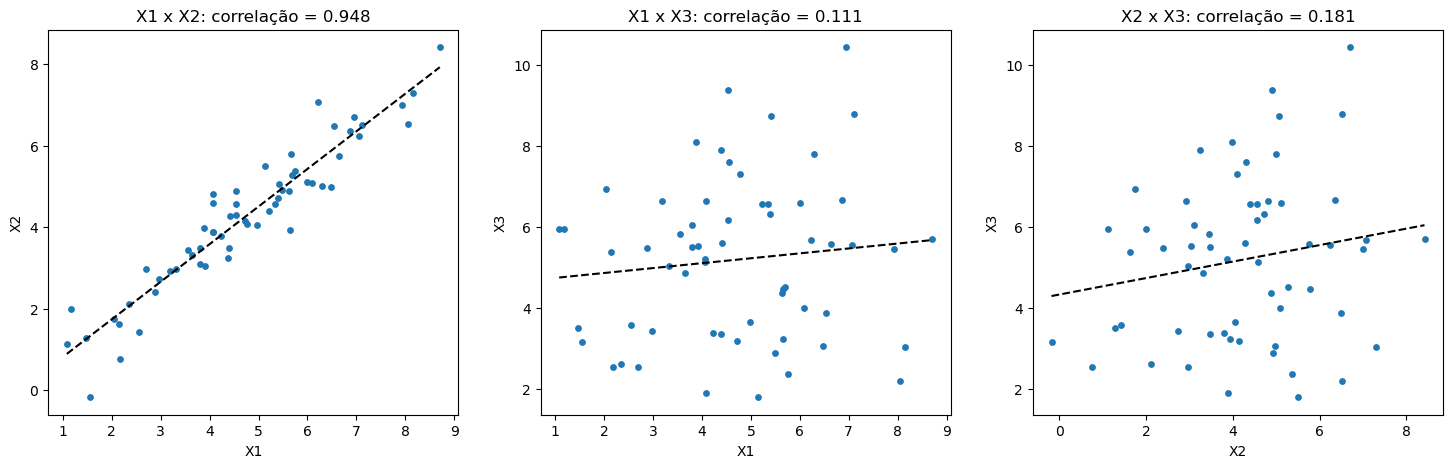

In [4]:
# Figura 10.2: projeção dos pontos em cada plano, com o ajuste linear tracejado
fig, ax = plt.subplots(1, 3, figsize = (18, 5))

for eixo, (a, b) in zip(ax, [("X1", "X2"), ("X1", "X3"), ("X2", "X3")]):
    eixo.scatter(hipotetico[a], hipotetico[b], s=15)
    inclinacao, intercepto = np.polyfit(hipotetico[a], hipotetico[b], 1)
    xs = np.linspace(hipotetico[a].min(), hipotetico[a].max(), 10)
    eixo.plot(xs, intercepto + inclinacao * xs, 'k--')
    eixo.set_xlabel(a)
    eixo.set_ylabel(b)
    eixo.set_title(f'{a} x {b}: correlação = {np.round(hipotetico[a].corr(hipotetico[b]), 3)}')

# Exibir o gráfico
plt.show()

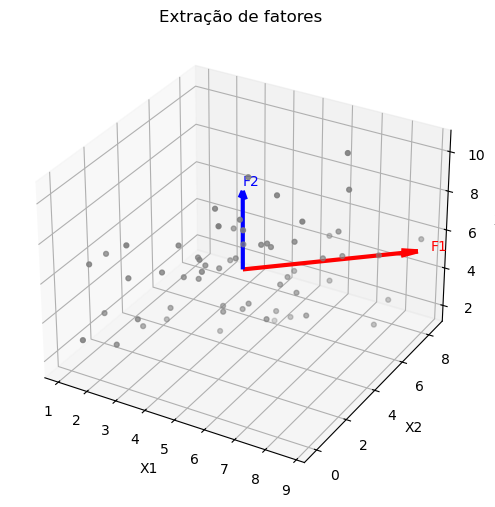

In [5]:
# Figura 10.4: extração dos fatores F1 (direção comum de X1 e X2) e F2 (direção de X3)
fig = plt.figure(figsize = (8, 6))
ax = fig.add_subplot(projection='3d')
ax.scatter(x1, x2, x3, color='gray', s=12)

centro = hipotetico.mean().values
ax.quiver(*centro, 4, 4, 0, color='red', linewidth=3, arrow_length_ratio=0.1)
ax.quiver(*centro, 0, 0, 4, color='blue', linewidth=3, arrow_length_ratio=0.1)
ax.text(*(centro + [4.3, 4.3, 0]), 'F1', color='red')
ax.text(*(centro + [0, 0, 4.3]), 'F2', color='blue')

ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('X3')
ax.set_title('Extração de fatores')

# Exibir o gráfico
plt.show()

Note que $X_1$ e $X_2$ podem ser bem representadas por um único fator $F_1$, enquanto $X_3$ precisa de outro fator $F_2$, ortogonal a $F_1$. Os fatores são, portanto, dimensões latentes que explicam o comportamento das variáveis originais.

## **Exemplo: Notas de Finanças, Custos, Marketing e Atuária**

Um professor levantou as notas finais (0 a 10) de 100 alunos em Finanças, Custos, Marketing e Atuária e quer estudar o comportamento conjunto das notas para criar um ranking de desempenho.

O livro apresenta a matriz de correlações calculada com os 100 alunos (Tabela 10.6), e toda a análise fatorial parte dela.

In [6]:
variaveis = ["financas", "custos", "marketing", "atuaria"]

rho = pd.DataFrame([[1.000, 0.756, -0.030, 0.711],
                    [0.756, 1.000, 0.003, 0.809],
                    [-0.030, 0.003, 1.000, -0.044],
                    [0.711, 0.809, -0.044, 1.000]],
                   index=variaveis, columns=variaveis)

n_alunos = 100
k = len(variaveis)

print(f"Determinante da matriz de correlações: {np.round(np.linalg.det(rho), 3)}")
rho

Determinante da matriz de correlações: 0.137


,financas,custos,marketing,atuaria
financas,1.000,0.756,-0.030,0.711
custos,0.756,1.000,0.003,0.809
marketing,-0.030,0.003,1.000,-0.044
atuaria,0.711,0.809,-0.044,1.000


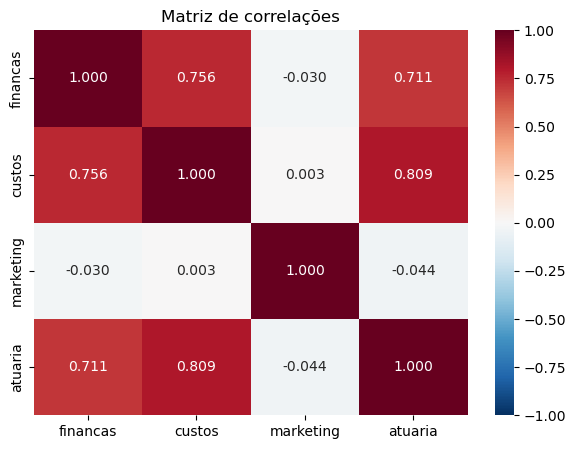

In [7]:
plt.figure(figsize = (7, 5))
sns.heatmap(rho, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, fmt='.3f')
plt.title('Matriz de correlações')

# Exibir o gráfico
plt.show()

Note que finanças, custos e atuária têm correlações altas entre si (0.756, 0.711 e 0.809), enquanto marketing praticamente não se relaciona com as demais. É um primeiro indício de que finanças, custos e atuária vão formar um fator e marketing outro.

## **Adequação Global da Análise Fatorial**

Antes de extrair os fatores, verificamos se as correlações são altas e significantes o suficiente.

### **Estatística KMO (Kaiser-Meyer-Olkin)**

Mede a proporção de variância comum a todas as variáveis, comparando as correlações de Pearson $\rho$ com as correlações parciais $\varphi$:

$KMO = \frac{\sum_{l}\sum_{c}\rho_{lc}^2}{\sum_{l}\sum_{c}\rho_{lc}^2 + \sum_{l}\sum_{c}\varphi_{lc}^2}, \quad l \neq c$

A `correlação parcial` mede a correlação entre duas variáveis controlando o efeito das demais. Com três variáveis, a correlação de primeira ordem é:

$\varphi_{ab,c} = \frac{\rho_{ab} - \rho_{ac}\cdot\rho_{bc}}{\sqrt{(1-\rho_{ac}^2)\cdot(1-\rho_{bc}^2)}}$

e com quatro variáveis a de segunda ordem é:

$\varphi_{ab,cd} = \frac{\varphi_{ab,c} - \varphi_{ad,c}\cdot\varphi_{bd,c}}{\sqrt{(1-\varphi_{ad,c}^2)\cdot(1-\varphi_{bd,c}^2)}}$

| KMO | Adequação global |
|---|---|
| Entre 0.90 e 1.00 | Muito boa |
| Entre 0.80 e 0.90 | Boa |
| Entre 0.70 e 0.80 | Média |
| Entre 0.60 e 0.70 | Razoável |
| Entre 0.50 e 0.60 | Má |
| Menor que 0.50 | Inaceitável |

In [8]:
def correlacao_primeira_ordem(r, a, b, c):
    return (r.loc[a, b] - r.loc[a, c] * r.loc[b, c]) / np.sqrt((1 - r.loc[a, c]**2) * (1 - r.loc[b, c]**2))

def correlacao_segunda_ordem(r, a, b, c, d):
    ab_c = correlacao_primeira_ordem(r, a, b, c)
    ad_c = correlacao_primeira_ordem(r, a, d, c)
    bd_c = correlacao_primeira_ordem(r, b, d, c)
    return (ab_c - ad_c * bd_c) / np.sqrt((1 - ad_c**2) * (1 - bd_c**2))

# Exemplo: finanças e custos, controlando marketing e atuária
print(f"Primeira ordem (controlando marketing): {np.round(correlacao_primeira_ordem(rho, 'financas', 'custos', 'marketing'), 3)}")
print(f"Segunda ordem (controlando marketing e atuária): {np.round(correlacao_segunda_ordem(rho, 'financas', 'custos', 'marketing', 'atuaria'), 3)}")

Primeira ordem (controlando marketing): 0.756
Segunda ordem (controlando marketing e atuária): 0.438


Com muitas variáveis, o cálculo recursivo fica trabalhoso. Na prática, as correlações parciais de todas as ordens saem da inversa da matriz de correlações: $\varphi_{lc} = -\frac{\rho^{-1}_{lc}}{\sqrt{\rho^{-1}_{ll}\cdot\rho^{-1}_{cc}}}$.

In [9]:
def matriz_correlacao_parcial(r):
    inversa = np.linalg.inv(r)
    d = np.sqrt(np.diag(inversa))
    parcial = -inversa / np.outer(d, d)
    np.fill_diagonal(parcial, 1)
    return pd.DataFrame(parcial, index=r.index, columns=r.columns)

def kmo(r):
    parcial = matriz_correlacao_parcial(r).values
    fora_diagonal = ~np.eye(len(r), dtype=bool)
    soma_r2 = np.sum(r.values[fora_diagonal]**2)
    soma_p2 = np.sum(parcial[fora_diagonal]**2)
    return soma_r2 / (soma_r2 + soma_p2)

print(f"KMO: {np.round(kmo(rho), 3)}")
matriz_correlacao_parcial(rho).round(3)

KMO: 0.737


,financas,custos,marketing,atuaria
financas,1.000,0.438,-0.030,0.256
custos,0.438,1.000,0.072,0.592
marketing,-0.030,0.072,1.000,-0.069
atuaria,0.256,0.592,-0.069,1.000


Note que o KMO é 0.737, então a adequação global da análise fatorial é `média`. As correlações parciais batem com a Tabela 10.8 do livro (0.438 entre finanças e custos, 0.592 entre custos e atuária ...).

### **Teste de esfericidade de Bartlett**

Compara a matriz de correlações com a matriz identidade $I$:

$H_0: \rho = I$ (as variáveis não são correlacionadas e não há fatores a extrair)

$H_1: \rho \neq I$

$\chi^2_{Bartlett} = -\left[(n-1) - \frac{2\cdot k+5}{6}\right]\cdot\ln|D| \sim \chi^2_{k(k-1)/2}$

sendo $D$ o determinante da matriz de correlações.

`OBS:` *O livro recomenda decidir pelo teste de Bartlett, e não pelo KMO, porque o teste tem nível de significância. Com só duas variáveis, por exemplo, o KMO é sempre 0.50.*

In [10]:
def esfericidade_bartlett(r, n):
    k = len(r)
    estatistica = -((n - 1) - (2 * k + 5) / 6) * np.log(np.linalg.det(r))
    gl = k * (k - 1) / 2
    return estatistica, gl, chi2.sf(estatistica, gl)

chi2_bartlett, gl_bartlett, p_bartlett = esfericidade_bartlett(rho, n_alunos)

print(f"Qui-quadrado de Bartlett: {np.round(chi2_bartlett, 3)} ({int(gl_bartlett)} gl)")
print(f"Qui-quadrado crítico (5%): {np.round(chi2.ppf(0.95, gl_bartlett), 3)}")
print(f"P-value: {p_bartlett:.2e}")

Qui-quadrado de Bartlett: 192.358 (6 gl)
Qui-quadrado crítico (5%): 12.592
P-value: 8.02e-39


Note que $\chi^2_{Bartlett} = 192.358$ é muito maior que $\chi^2_c = 12.592$ (P-value da ordem de $10^{-39}$), então rejeitamos $H_0$: a matriz de correlações é diferente da identidade, e a análise fatorial é apropriada. O livro chega a 192.335, e a pequena diferença vem do arredondamento do determinante (0.137).

## **Extração dos Fatores por Componentes Principais**

Os fatores são combinações lineares das variáveis padronizadas:

$F_{1i} = s_{11}\cdot ZX_{1i} + s_{21}\cdot ZX_{2i} + \cdots + s_{k1}\cdot ZX_{ki}$

$\vdots$

$F_{ki} = s_{1k}\cdot ZX_{1i} + s_{2k}\cdot ZX_{2i} + \cdots + s_{kk}\cdot ZX_{ki}$

Os coeficientes $s$ são os `scores fatoriais`, obtidos a partir dos autovalores $\lambda^2$ e autovetores $v$ da matriz de correlações:

$det(\lambda^2\cdot I - \rho) = 0, \quad \lambda_1^2 \geq \lambda_2^2 \geq \cdots \geq \lambda_k^2, \quad \sum_{j=1}^{k}\lambda_j^2 = k$

$s_{lj} = \frac{v_{lj}}{\sqrt{\lambda_j^2}}$

* `Critério da raiz latente (Kaiser):` ficamos só com os fatores de autovalor maior que 1, porque um fator com autovalor menor que 1 não representa sequer uma variável original.
* Cada autovalor dividido por $k$ é a parcela da variância total compartilhada na formação daquele fator.

In [11]:
autovalores, autovetores = np.linalg.eigh(rho)

# Ordenar do maior para o menor autovalor
ordem = np.argsort(autovalores)[::-1]
autovalores = autovalores[ordem]
autovetores = autovetores[:, ordem]

# Convenção de sinal: coeficiente de finanças positivo em cada autovetor (como no livro)
autovetores = autovetores * np.sign(autovetores[0, :])

fatores = [f"F{j+1}" for j in range(k)]
print(f"Soma dos autovalores: {np.round(autovalores.sum(), 3)}")

pd.DataFrame(autovetores, index=variaveis, columns=fatores).round(4)

Soma dos autovalores: 4.0


,F1,F2,F3,F4
financas,0.5642,0.0064,0.8006,0.2019
custos,0.5887,0.0487,-0.2194,-0.7765
marketing,-0.0267,0.9987,0.0002,0.0423
atuaria,0.5783,-0.0096,-0.5576,0.5954


In [12]:
# Variância compartilhada para a formação de cada fator (Tabela 10.9)
variancia = pd.DataFrame({
    "Autovalor": autovalores,
    "Variância compartilhada (%)": autovalores / k * 100,
    "Variância acumulada (%)": np.cumsum(autovalores) / k * 100
}, index=fatores)
variancia.round(3)

,Autovalor,Variância compartilhada (%),Variância acumulada (%)
F1,2.519,62.978,62.978
F2,1.000,25.009,87.988
F3,0.298,7.439,95.427
F4,0.183,4.573,100.000


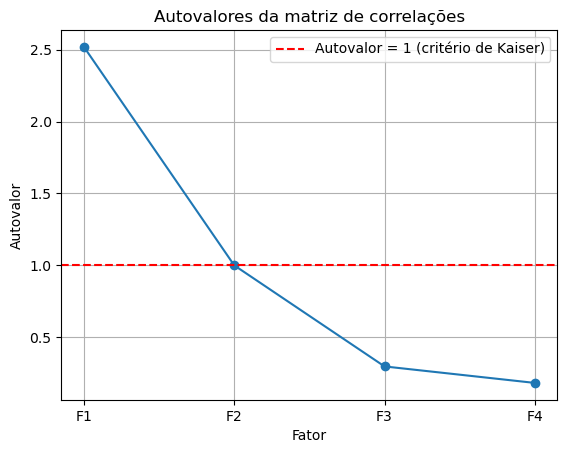

In [13]:
# Gráfico dos autovalores (scree plot) com o critério de Kaiser
plt.plot(range(1, k + 1), autovalores, 'o-')
plt.axhline(1, color='red', linestyle='--', label='Autovalor = 1 (critério de Kaiser)')
plt.xticks(range(1, k + 1), fatores)
plt.xlabel('Fator')
plt.ylabel('Autovalor')
plt.title('Autovalores da matriz de correlações')
plt.legend()
plt.grid(True)

# Exibir o gráfico
plt.show()

Note que os autovalores são 2.519, 1.000, 0.298 e 0.183, como no livro. Pelo critério de Kaiser ficamos com os dois primeiros fatores, que juntos compartilham 87.985% da variância total, ou seja, perdemos 12.015% da variância das variáveis originais.

`OBS:` *O segundo autovalor fica exatamente em 1.000, no limite do critério. O livro mantém o fator, que, como veremos, é praticamente a própria nota de marketing.*

In [14]:
# Conferindo a relação V' . rho . V = matriz de autovalores
(autovetores.T @ rho.values @ autovetores).round(3)

array([[ 2.519, -0.   , -0.   ,  0.   ],
       [-0.   ,  1.   , -0.   ,  0.   ],
       [-0.   , -0.   ,  0.298, -0.   ],
       [ 0.   ,  0.   , -0.   ,  0.183]])

In [15]:
# Scores fatoriais
scores_fatoriais = pd.DataFrame(autovetores / np.sqrt(autovalores), index=variaveis, columns=fatores)
scores_fatoriais.round(3)

,F1,F2,F3,F4
financas,0.355,0.006,1.468,0.472
custos,0.371,0.049,-0.402,-1.815
marketing,-0.017,0.999,0.000,0.099
atuaria,0.364,-0.010,-1.022,1.392


Com os scores fatoriais, os fatores ficam:

$F_{1i} = 0.355\cdot Zfinanças_i + 0.371\cdot Zcustos_i - 0.017\cdot Zmarketing_i + 0.364\cdot Zatuária_i$

$F_{2i} = 0.007\cdot Zfinanças_i + 0.049\cdot Zcustos_i + 0.999\cdot Zmarketing_i - 0.010\cdot Zatuária_i$

e assim por diante. Vamos conferir com as notas padronizadas dos alunos que o livro mostra na Tabela 10.10:

In [16]:
z_livro = pd.DataFrame({
    "financas": [-0.011, -0.876, -0.876, 1.334, -0.779, 1.334, -0.267, -0.139, 0.021, 0.982],
    "custos": [-0.290, -0.697, -0.290, 1.337, -1.104, 2.150, 0.116, 0.523, -0.290, 0.113],
    "marketing": [-1.650, 1.532, -0.590, 0.825, -0.872, -1.650, 0.825, 0.118, -0.590, -1.297],
    "atuaria": [0.273, -1.319, -0.523, 1.069, -0.841, 1.865, -0.125, 0.273, -0.523, 1.069]
}, index=["Gabriela", "Luiz Felipe", "Patrícia", "Gustavo", "Letícia",
          "Ovídio", "Leonor", "Dalila", "Antônio", "Estela"])

(z_livro @ scores_fatoriais).round(3)

,F1,F2,F3,F4
Gabriela,0.016,-1.664,-0.179,0.738
Luiz Felipe,-1.076,1.503,0.344,-0.833
Patrícia,-0.600,-0.604,-0.635,-0.673
Gustavo,1.346,0.887,0.328,-0.228
Letícia,-0.978,-0.921,0.160,0.380
Ovídio,1.979,-1.552,-0.814,-0.841
Leonor,-0.111,0.829,-0.310,-0.429
Dalila,0.242,0.140,-0.693,-0.623
Antônio,-0.281,-0.598,0.682,-0.250
Estela,0.802,-1.294,0.303,1.618


Note que os valores dos fatores batem com a Tabela 10.10 do livro (por exemplo, $F_1 = 0.016$ e $F_2 = -1.665$ para Gabriela).

## **Cargas Fatoriais e Comunalidades**

* `Cargas fatoriais:` são as correlações de Pearson entre cada variável e cada fator, $c_{lj} = v_{lj}\cdot\sqrt{\lambda_j^2}$. A soma dos quadrados das cargas de uma coluna é o autovalor daquele fator.
* `Comunalidade:` soma dos quadrados das cargas de uma variável nos fatores extraídos. É a parcela da variância da variável compartilhada com esses fatores, e comunalidades muito baixas sugerem retirar a variável da análise.

$c_{11}^2 + c_{12}^2 + \cdots = comunalidade_{X_1}$

In [17]:
cargas = pd.DataFrame(autovetores * np.sqrt(autovalores), index=variaveis, columns=fatores)

print("Soma dos quadrados das cargas em cada coluna (autovalores):")
print((cargas**2).sum().round(3).to_dict())
cargas.round(3)

Soma dos quadrados das cargas em cada coluna (autovalores):
{'F1': 2.519, 'F2': 1.0, 'F3': 0.298, 'F4': 0.183}


,F1,F2,F3,F4
financas,0.895,0.006,0.437,0.086
custos,0.934,0.049,-0.120,-0.332
marketing,-0.042,0.999,0.000,0.018
atuaria,0.918,-0.010,-0.304,0.255


In [18]:
# Comunalidades considerando os dois fatores extraídos
fatores_extraidos = ["F1", "F2"]
comunalidades = (cargas[fatores_extraidos]**2).sum(axis=1)
comunalidades.round(3)

financas     0.802
custos       0.875
marketing    1.000
atuaria      0.843
dtype: float64

Note que finanças, custos e atuária têm carga alta no primeiro fator (0.895, 0.934 e 0.918) e marketing tem carga alta só no segundo (0.999). Pelas comunalidades, marketing é a variável que menos perde variância com os dois fatores (1.000), e finanças a que mais perde (cerca de 19.8%).

`OBS:` *As cargas fatoriais são os coeficientes de uma regressão da variável padronizada nos fatores, e o $R^2$ dessa regressão é a comunalidade. Já os scores fatoriais são os coeficientes da regressão do fator nas variáveis padronizadas.*

### **Loading plot**

O `loading plot` posiciona cada variável usando suas cargas como coordenadas no plano formado pelos fatores.

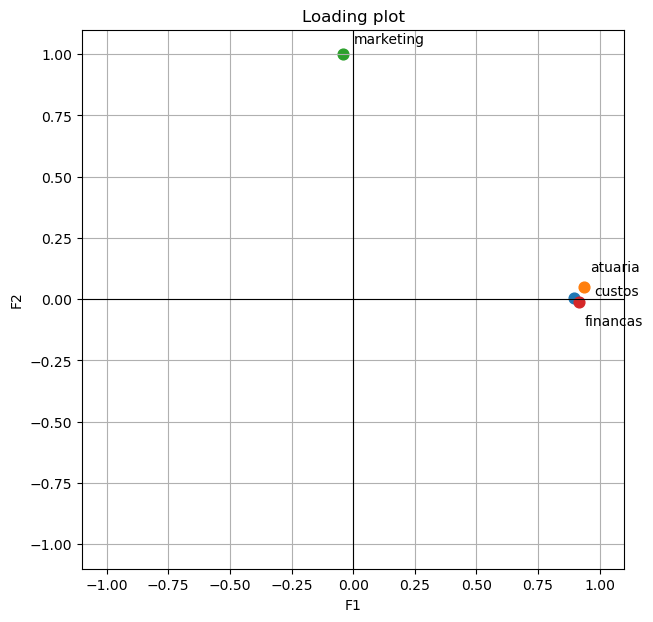

In [19]:
def loading_plot(cargas, titulo, eixos=("F1", "F2")):

    fig, ax = plt.subplots(figsize = (7, 7))
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)

    for i, (variavel, linha) in enumerate(cargas.iterrows()):
        ax.scatter(linha[eixos[0]], linha[eixos[1]], s=60)
        # Rótulos escalonados para não se sobreporem quando as cargas são parecidas
        ax.annotate(variavel, (linha[eixos[0]], linha[eixos[1]]), xytext=(8, 14 * i - 20),
                    textcoords='offset points', fontsize=10)

    ax.set_xlim(-1.1, 1.1)
    ax.set_ylim(-1.1, 1.1)
    ax.set_xlabel(eixos[0])
    ax.set_ylabel(eixos[1])
    ax.set_title(titulo)
    ax.grid(True)

    # Exibir o gráfico
    plt.show()

# Figura 10.8: loading plot
loading_plot(cargas, 'Loading plot')

Note que finanças, custos e atuária ficam juntas perto do eixo do primeiro fator, e marketing sozinha no eixo do segundo. Uma explicação possível é que Finanças, Custos e Atuária são disciplinas mais quantitativas e Marketing mais qualitativa e comportamental.

`OBS:` *A análise fatorial não obriga a dar nome aos fatores. Isso exige conhecimento profundo do fenômeno estudado.*

## **Rotação de Fatores**

Quando algumas variáveis têm cargas intermediárias em todos os fatores, podemos `rotacionar` os fatores em torno da origem para aumentar as cargas de cada variável em um fator e diminuir nos demais, o que facilita a interpretação. Veja a ideia com uma situação hipotética, como nas Figuras 10.5 e 10.6 do livro:

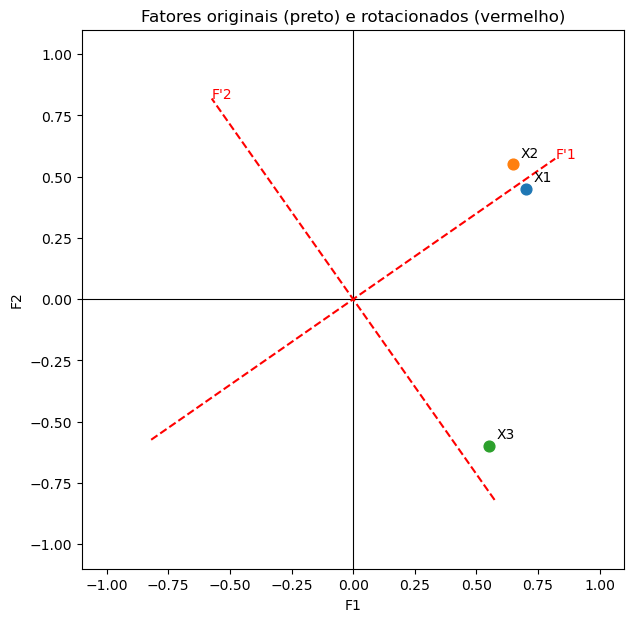

In [20]:
# Figuras 10.5 e 10.6: loading plot hipotético e fatores rotacionados
cargas_hipoteticas = pd.DataFrame({"F1": [0.70, 0.65, 0.55], "F2": [0.45, 0.55, -0.60]}, index=["X1", "X2", "X3"])
angulo = np.radians(35)

fig, ax = plt.subplots(figsize = (7, 7))
ax.axhline(0, color='black', linewidth=0.8)
ax.axvline(0, color='black', linewidth=0.8)

# Eixos dos fatores rotacionados F'1 e F'2
for (dx, dy), nome in [((np.cos(angulo), np.sin(angulo)), "F'1"), ((-np.sin(angulo), np.cos(angulo)), "F'2")]:
    ax.plot([-dx, dx], [-dy, dy], 'r--')
    ax.text(dx, dy, nome, color='red')

for variavel, linha in cargas_hipoteticas.iterrows():
    ax.scatter(linha["F1"], linha["F2"], s=60)
    ax.text(linha["F1"] + 0.03, linha["F2"] + 0.03, variavel)

ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.set_xlabel('F1')
ax.set_ylabel('F2')
ax.set_title('Fatores originais (preto) e rotacionados (vermelho)')

# Exibir o gráfico
plt.show()

Note que, ao girar os eixos, X1 e X2 ficam mais próximas de $F'_1$ e X3 mais próxima de $F'_2$.

A rotação não muda as comunalidades, a variância total compartilhada, o KMO nem o teste de Bartlett, mas `redistribui` a variância entre os fatores, gerando novos autovalores.

### **Rotação Varimax**

É a rotação ortogonal mais usada (Kaiser, 1958). Para um par de fatores, as cargas rotacionadas são:

$\begin{bmatrix} c'_{11} & c'_{12} \\ \vdots & \vdots \\ c'_{k1} & c'_{k2} \end{bmatrix} = \begin{bmatrix} c_{11} & c_{12} \\ \vdots & \vdots \\ c_{k1} & c_{k2} \end{bmatrix}\cdot\begin{bmatrix} cos\theta & -sen\theta \\ sen\theta & cos\theta \end{bmatrix}$

com o ângulo de rotação

$\theta = 0.25\cdot arctan\left[\frac{2\cdot(D\cdot k - A\cdot B)}{C\cdot k - (A^2 - B^2)}\right]$

sendo, com $h_l = comunalidade_l$:

$A = \sum_{l=1}^{k}\left(\frac{c_{l1}^2}{h_l} - \frac{c_{l2}^2}{h_l}\right) \quad B = \sum_{l=1}^{k}\left(2\cdot\frac{c_{l1}\cdot c_{l2}}{h_l}\right)$

$C = \sum_{l=1}^{k}\left[\left(\frac{c_{l1}^2}{h_l} - \frac{c_{l2}^2}{h_l}\right)^2 - \left(2\cdot\frac{c_{l1}\cdot c_{l2}}{h_l}\right)^2\right] \quad D = \sum_{l=1}^{k}\left[\left(\frac{c_{l1}^2}{h_l} - \frac{c_{l2}^2}{h_l}\right)\cdot\left(2\cdot\frac{c_{l1}\cdot c_{l2}}{h_l}\right)\right]$

`OBS:` *Outras rotações ortogonais são a Quartimax e a Equimax. As rotações oblíquas (Direct Oblimin e Promax) geram fatores correlacionados.*

In [21]:
def varimax_dois_fatores(cargas):

    c1, c2 = cargas.iloc[:, 0].values, cargas.iloc[:, 1].values
    h = c1**2 + c2**2  # Comunalidades
    k = len(c1)

    u = c1**2 / h - c2**2 / h
    v = 2 * c1 * c2 / h
    A, B = u.sum(), v.sum()
    C = np.sum(u**2 - v**2)
    D = np.sum(u * v)

    theta = 0.25 * np.arctan2(2 * (D * k - A * B), C * k - (A**2 - B**2))
    rotacao = np.array([[np.cos(theta), -np.sin(theta)],
                        [np.sin(theta), np.cos(theta)]])

    print(f"A = {np.round(A, 3)} | B = {np.round(B, 3)} | C = {np.round(C, 3)} | D = {np.round(D, 3)}")
    print(f"Ângulo de rotação: {np.round(theta, 3)} rad")

    rotacionadas = pd.DataFrame(cargas.values @ rotacao, index=cargas.index, columns=["F'1", "F'2"])
    return rotacionadas, rotacao

cargas_rotacionadas, matriz_rotacao = varimax_dois_fatores(cargas[fatores_extraidos])
cargas_rotacionadas.round(3)

A = 1.998 | B = 0.012 | C = 3.963 | D = 0.181
Ângulo de rotação: 0.029 rad


,F'1,F'2
financas,0.895,-0.020
custos,0.935,0.021
marketing,-0.013,1.000
atuaria,0.917,-0.037


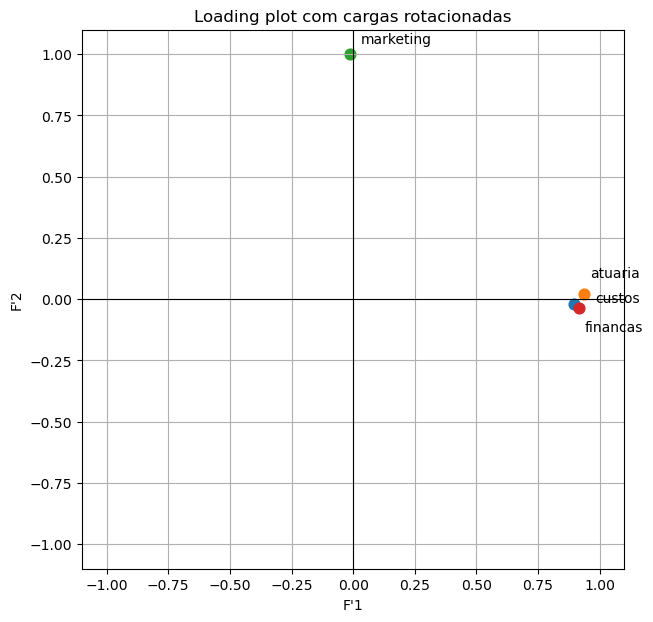

In [22]:
# Figura 10.9: loading plot com cargas rotacionadas
loading_plot(cargas_rotacionadas, 'Loading plot com cargas rotacionadas', eixos=("F'1", "F'2"))

In [23]:
# A rotação não muda as comunalidades, mas redistribui os autovalores (Tabela 10.17)
print("Comunalidades:", (cargas_rotacionadas**2).sum(axis=1).round(3).to_dict())

autovalores_rotacionados = (cargas_rotacionadas**2).sum()
pd.DataFrame({"Autovalor": autovalores_rotacionados,
              "Variância compartilhada (%)": autovalores_rotacionados / k * 100,
              "Variância acumulada (%)": np.cumsum(autovalores_rotacionados) / k * 100}).round(3)

Comunalidades: {'financas': 0.802, 'custos': 0.875, 'marketing': 1.0, 'atuaria': 0.843}


,Autovalor,Variância compartilhada (%),Variância acumulada (%)
F'1,2.518,62.945,62.945
F'2,1.002,25.042,87.988


Note que o ângulo de rotação é pequeno (0.029 rad), porque o loading plot já era bem claro, então as cargas quase não mudam. Os autovalores passam de 2.519 e 1.000 para 2.518 e 1.002, e a variância total compartilhada continua 87.988%. A rotação só redistribuiu a variância entre os fatores.

In [24]:
# Scores fatoriais rotacionados: F' = Z . S . R
scores_rotacionados = pd.DataFrame(scores_fatoriais[fatores_extraidos].values @ matriz_rotacao,
                                   index=variaveis, columns=["F'1", "F'2"])
scores_rotacionados.round(3)

,F'1,F'2
financas,0.355,-0.004
custos,0.372,0.038
marketing,0.012,0.999
atuaria,0.364,-0.020


Com isso, os fatores rotacionados são:

$F'_{1i} = 0.355\cdot Zfinanças_i + 0.372\cdot Zcustos_i + 0.012\cdot Zmarketing_i + 0.364\cdot Zatuária_i$

$F'_{2i} = -0.004\cdot Zfinanças_i + 0.038\cdot Zcustos_i + 0.999\cdot Zmarketing_i - 0.021\cdot Zatuária_i$

## **Ranking de Desempenho**

Um critério bem aceito para criar rankings a partir de fatores é o da `soma ponderada e ordenamento`: somamos os valores dos fatores com autovalor maior que 1, ponderados pela variância compartilhada de cada um, e ordenamos as observações. Ele considera o desempenho em todas as variáveis, e não só no fator principal.

$Desempenho_i = F'_{1i}\cdot 0.62942 + F'_{2i}\cdot 0.25043$

Primeiro, conferimos com os alunos que o livro mostra na Tabela 10.18:

In [25]:
z_ranking_livro = pd.DataFrame({
    "financas": [1.30, 0.60, 1.33, 1.33, -1.29, -0.88, -0.01, 0.50, -1.64, -1.52],
    "custos": [2.15, 2.15, 2.15, 2.07, -0.55, -0.70, -0.29, -0.50, -1.16, -1.16],
    "marketing": [1.53, 1.53, -1.65, -1.65, 1.53, 1.53, -1.65, -0.94, -1.01, -1.40],
    "atuaria": [1.86, 1.86, 1.86, 1.86, -1.04, -1.32, 0.27, -1.16, -1.00, -1.44]
}, index=["Adelino", "Renata", "Ovídio", "Kamal", "Itamar", "Luiz Felipe",
          "Gabriela", "Marina", "Viviane", "Gilmar"])

pesos = autovalores_rotacionados.values / k

ranking_livro = z_ranking_livro @ scores_rotacionados
ranking_livro["Desempenho"] = ranking_livro.values @ pesos
ranking_livro.round(3)

,F'1,F'2,Desempenho
Adelino,1.958,1.566,1.625
Renata,1.709,1.569,1.469
Ovídio,1.929,-1.610,0.811
Kamal,1.899,-1.613,0.792
Itamar,-1.023,1.533,-0.260
Luiz Felipe,-1.035,1.532,-0.268
Gabriela,-0.034,-1.664,-0.438
Marina,-0.442,-0.936,-0.513
Viviane,-1.391,-1.025,-1.133
Gilmar,-1.514,-1.406,-1.305


Note que os valores batem com a Tabela 10.18 (Adelino: $F'_1 = 1.959$, $F'_2 = 1.568$ e desempenho 1.626).

O livro não traz as notas dos 100 alunos (a base completa está no arquivo `NotasFatorial.xls` da editora). Para montar o ranking completo, vamos simular 100 alunos com `exatamente` a mesma matriz de correlações do livro.

In [26]:
np.random.seed(42)

# Gerando dados com a matriz de correlações exata do livro
z = np.random.normal(size=(n_alunos, k))
z = (z - z.mean(axis=0)) @ np.linalg.inv(np.linalg.cholesky(np.cov(z, rowvar=False)).T)
z = z @ np.linalg.cholesky(rho.values).T

notas_alunos = pd.DataFrame(np.clip(6 + 1.5 * z, 0, 10), columns=variaveis)
notas_alunos.index = [f"Aluno {i+1}" for i in range(n_alunos)]

print(f"Maior diferença em relação às correlações do livro: {np.round(np.abs(notas_alunos.corr() - rho).values.max(), 4)}")
notas_alunos.describe().round(2)

Maior diferença em relação às correlações do livro: 0.007


,financas,custos,marketing,atuaria
count,100.00,100.00,100.00,100.00
mean,6.00,5.99,6.00,6.00
std,1.50,1.48,1.50,1.50
min,2.52,3.19,1.38,3.26
25%,4.78,4.88,5.18,4.84
50%,6.02,5.79,6.07,5.92
75%,6.93,6.96,7.03,7.09
max,10.00,10.00,9.06,9.62


In [27]:
# Padronização (Zscores), fatores rotacionados e ranking
z_alunos = (notas_alunos - notas_alunos.mean()) / notas_alunos.std()

ranking = z_alunos @ scores_rotacionados
ranking["Desempenho"] = ranking.values @ pesos
ranking["Ranking"] = ranking["Desempenho"].rank(ascending=False).astype(int)
ranking = ranking.sort_values("Ranking")

print("Correlação entre os fatores rotacionados:", np.round(ranking["F'1"].corr(ranking["F'2"]), 3))
pd.concat([ranking.head(5), ranking.tail(5)]).round(3)

Correlação entre os fatores rotacionados: -0.001


,F'1,F'2,Desempenho,Ranking
Aluno 94,1.730,2.075,1.608,1
Aluno 53,2.110,0.838,1.538,2
Aluno 64,2.502,-1.462,1.209,3
Aluno 42,1.565,0.739,1.170,4
Aluno 40,2.260,-1.204,1.121,5
Aluno 12,-1.617,-0.485,-1.139,96
Aluno 26,-1.828,-0.324,-1.232,97
Aluno 96,-1.245,-2.072,-1.302,98
Aluno 60,-1.881,-0.566,-1.326,99
Aluno 66,-1.238,-3.080,-1.550,100


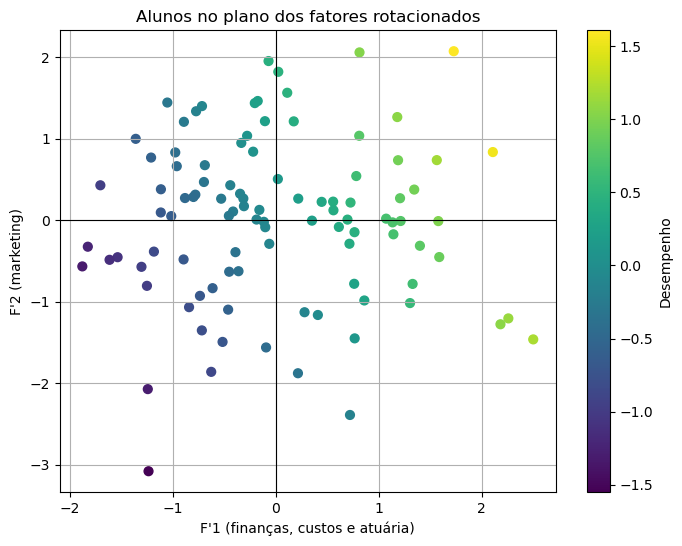

In [28]:
plt.figure(figsize = (8, 6))
plt.scatter(ranking["F'1"], ranking["F'2"], c=ranking["Desempenho"], cmap='viridis', s=40)
plt.colorbar(label='Desempenho')
plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel("F'1 (finanças, custos e atuária)")
plt.ylabel("F'2 (marketing)")
plt.title('Alunos no plano dos fatores rotacionados')
plt.grid(True)

# Exibir o gráfico
plt.show()

Note que os fatores rotacionados têm correlação 0 entre si (são ortogonais) e que os alunos do topo do ranking vão bem nos dois fatores.

`OBS:` *Rankings feitos a partir de fatores também são estáticos: novas observações, novas variáveis ou a simples passagem do tempo mudam a matriz de correlações, e a análise precisa ser refeita. Os fatores também podem ser usados em outras técnicas, como análise de agrupamentos ou regressão.*

## **Apêndice: Alpha de Cronbach**

Mede a `consistência interna` das variáveis, ou seja, a confiabilidade com que um único fator pode ser extraído delas:

$\alpha = \frac{k}{k-1}\cdot\left[1 - \frac{\sum_{k}var_k}{var_{soma}}\right]$

sendo $var_k$ a variância de cada variável e $var_{soma}$ a variância da soma das variáveis de cada observação.

* Se as variáveis forem consistentes, $var_{soma}$ fica grande e $\alpha$ tende a 1.
* Valores acima de 0.6 costumam ser considerados aceitáveis em técnicas exploratórias.

`OBS:` *O alpha de Cronbach não substitui o KMO e o teste de Bartlett, porque só avalia a extração de um único fator.*

In [29]:
def alpha_cronbach(r):
    # Com variáveis padronizadas: cada variância vale 1 e a variância da soma é a soma de todos os elementos de r
    k = len(r)
    var_soma = r.values.sum()
    return k / (k - 1) * (1 - k / var_soma)

print(f"Variância da soma das variáveis padronizadas: {np.round(rho.values.sum(), 3)}")
print(f"Alpha de Cronbach: {np.round(alpha_cronbach(rho), 3)}")

Variância da soma das variáveis padronizadas: 8.41
Alpha de Cronbach: 0.699


In [30]:
# Alpha de Cronbach quando cada variável é excluída
pd.Series({variavel: alpha_cronbach(rho.drop(index=variavel, columns=variavel)) for variavel in variaveis},
          name="Alpha sem a variável").round(3)

financas     0.508
custos       0.447
marketing    0.904
atuaria      0.491
Name: Alpha sem a variável, dtype: float64

Note que o alpha de Cronbach é 0.699, acima de 0.6. Se excluirmos marketing, ele sobe para 0.904, e excluir qualquer outra variável o derruba. Isso confirma o que a análise fatorial mostrou: marketing não compartilha o mesmo fator que finanças, custos e atuária.

## **Exercícios Análise Fatorial**

### Exercício 1

Analistas de CRM de um banco fizeram uma análise fatorial com idade, percentual aplicado em renda fixa (`rfixa`), percentual aplicado em renda variável (`rvariavel`) e quantidade de pessoas na residência (`pessoas`). As cargas dos dois fatores extraídos foram:

In [31]:
cargas_crm = pd.DataFrame({"Fator 1": [0.917, 0.874, -0.844, 0.031],
                           "Fator 2": [0.047, 0.077, 0.197, 0.979]},
                          index=["idade", "rfixa", "rvariavel", "pessoas"])
cargas_crm

,Fator 1,Fator 2
idade,0.917,0.047
rfixa,0.874,0.077
rvariavel,-0.844,0.197
pessoas,0.031,0.979


In [32]:
#A) e B) Autovalores e variância compartilhada
autovalores_crm = (cargas_crm**2).sum()
variancia_crm = pd.DataFrame({"Autovalor": autovalores_crm,
                              "Variância compartilhada (%)": autovalores_crm / 4 * 100})
print(f"Variância total perdida: {np.round(100 - variancia_crm['Variância compartilhada (%)'].sum(), 2)}%")
variancia_crm.round(3)

Variância total perdida: 16.91%


,Autovalor,Variância compartilhada (%)
Fator 1,2.318,57.952
Fator 2,1.005,25.135


In [33]:
#C) Comunalidades
(cargas_crm**2).sum(axis=1).round(3)

idade        0.843
rfixa        0.770
rvariavel    0.751
pessoas      0.959
dtype: float64

In [34]:
#D) Cada variável padronizada em função dos fatores
for variavel, linha in cargas_crm.iterrows():
    print(f"Z{variavel} = {linha['Fator 1']:.3f} * F1 + {linha['Fator 2']:.3f} * F2")

Zidade = 0.917 * F1 + 0.047 * F2
Zrfixa = 0.874 * F1 + 0.077 * F2
Zrvariavel = -0.844 * F1 + 0.197 * F2
Zpessoas = 0.031 * F1 + 0.979 * F2


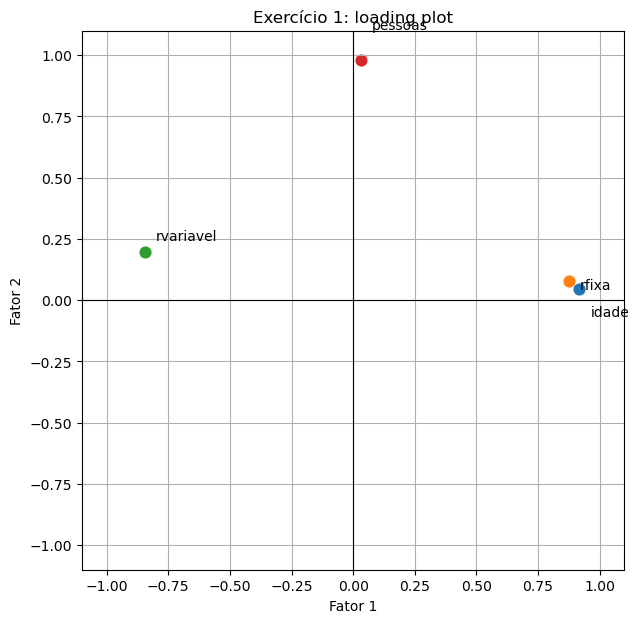

In [35]:
#E) Loading plot
loading_plot(cargas_crm, 'Exercício 1: loading plot', eixos=("Fator 1", "Fator 2"))

Note que:
* `Autovalores:` 2.318 para o fator 1 (57.95% da variância) e 1.005 para o fator 2 (25.14%), com perda total de 16.91% da variância das quatro variáveis.
* `Comunalidades:` pessoas (0.959) e idade (0.843) são as mais bem representadas, e renda variável (0.751) a que mais perde variância.
* `Interpretação:` o fator 1 junta idade e renda fixa com sinal positivo e renda variável com sinal negativo, então representa o `perfil de investimento`, com clientes mais velhos mais conservadores. O fator 2 é praticamente a quantidade de pessoas na residência, ou seja, o `tamanho da família`.

### Exercícios 2 e 3

Os exercícios 2 (`IndicadorPaíses.dta`, indicadores de 50 países em dois anos) e 3 (`PercepçãoDrogaria.dta`, percepção de 1.700 clientes sobre oito atributos de uma drogaria) usam bases que acompanham o livro e não estão neste repositório.

`OBS:` *Para resolvê-los, coloque as bases na pasta `dados/` e aplique as funções deste notebook (`kmo`, `esfericidade_bartlett`, autovalores com `np.linalg.eigh`, `loading_plot` e a rotação Varimax).*